
# 1. simulazioni esponenziali per tempi di vita

In [1]:
import numpy as np
import pandas as pd
from itertools import cycle
from matplotlib.path import Path as MplPath
import tifffile
import sys
from pathlib import Path
import plotly.graph_objects as go


#librerie personali (da sistemare perché fanno schifo)

import random
# from scipy.stats import norm, chi2
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost
import sys

import lib.randgen
import lib.my_stats



<h3> Initial information

In [ ]:
# estimate of tau 

τ_true = 4.0 # ns
N_evt = 10000

┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ τ    │   3.97    │   0.04    │            │            │         │         │       │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘

Fit result: tau = 3.971 ± 0.040 ns
True value: tau = 4.000 ns

Minuit statistics:
chi-squared: 16.88
reduced chi-squared: 1.21
dof: 14.00
p-value: 0.26


<h3> Method 1: Tau as arithmetical average of the data set

In [16]:
τ_fit, τ_err = np.mean(tempi), np.std(tempi) / np.sqrt(N_evt)

print(f"\nFit result: tau = {τ_fit:.3f} ± {τ_err:.3f} ns")
print(f"True value: tau = {τ_true:.3f} ns")

# calcolo chi quadrato e chi quadrato ridotto e pvalue
chi2 = np.sum((n - N_evt * (np.exp(-xe[:-1]/τ_fit) - np.exp(-xe[1:]/τ_fit)))**2 / (N_evt * (np.exp(-xe[:-1]/τ_fit) - np.exp(-xe[1:]/τ_fit))))
ndof = len(n) - 1
chi2_red = chi2 / ndof
p_value = 1 - stats.chi2.cdf(chi2, ndof)   

print(f"Chi-square: {chi2:.3f}")
print(f"Reduced Chi-square: {chi2_red:.3f}")
print(f"P-value: {p_value:.3f}")


Fit result: tau = 3.955 ± 0.040 ns
True value: tau = 4.000 ns
Chi-square: 16.064
Reduced Chi-square: 1.147
P-value: 0.309


<h3> Method 2: Tau as parameter from exponential fit


needed because first method is only good for a pure exponential and I will need to add noise in the future

In [7]:
# Uso la funzione nativa che applica la trasformata inversa in modo efficiente
tempi = np.random.exponential(scale = τ_true, size=N_evt)
n, xe = np.histogram(tempi, bins='sturges')


# CDF F(t) = 1 - e^(-t/tau)
# not using scipy version because I want tau as a parameter
def expon_cdf(x, τ):
    return 1.0 - np.exp(-x / τ)

ML = cost.BinnedNLL(n, xe, expon_cdf)
m = Minuit(ML, τ = 2.0)
m.migrad()

# function is asymmetric so minos method could be better... but it's slower so I will keep it here just in case 
# m.minos()

print(m.params)

τ_fit, τ_err = m.values["τ"], m.errors["τ"]

print(f"\nFit result: tau = {τ_fit:.3f} ± {τ_err:.3f} ns")
print(f"True value: tau = {τ_true:.3f} ns")

print(f"\nMinuit statistics:")
lib.my_stats.minuit_stats(m)

┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ τ    │   3.95    │   0.04    │            │            │         │         │       │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘

Fit result: tau = 3.949 ± 0.040 ns
True value: tau = 4.000 ns

Minuit statistics:
chi-squared: 16.93
reduced chi-squared: 1.21
dof: 14.00
p-value: 0.26


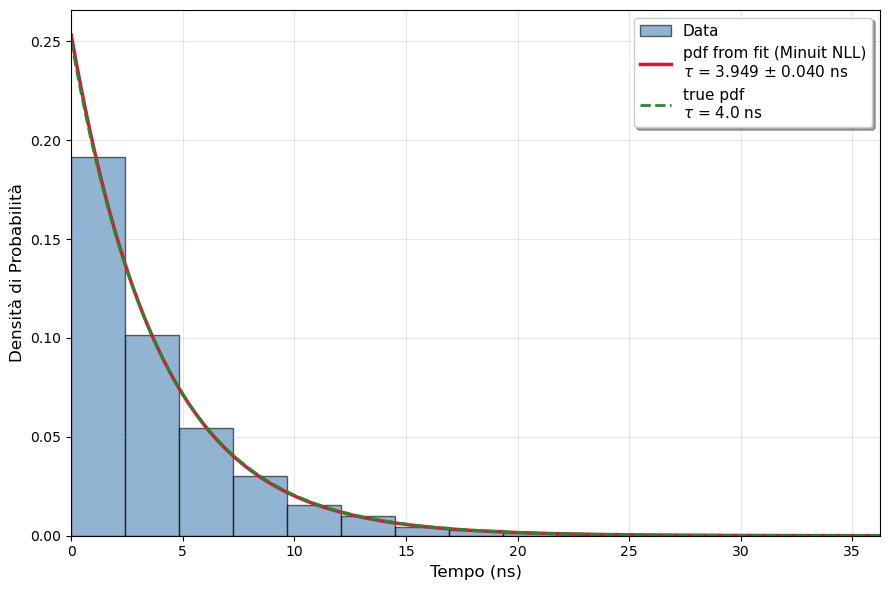

In [8]:
# histogram + fit plot + true plot  

plt.figure(figsize=(9, 6))

plt.hist(tempi, bins=xe, density=True, alpha=0.6, color='steelblue', 
         edgecolor='black', label='Data')                          #leaving all the details of the histogram so I can copy from here

x_plot = np.linspace(0, xe[-1], 500)  # rivedere qui che non ho capito bene cosa succede

# Calcolo la PDF fittata: f(x) = (1/tau) * e^(-x/tau)
pdf_fit = (1.0 / τ_fit) * np.exp(-x_plot / τ_fit)

# Calcolo anche la PDF vera, giusto per vedere quanto ci siamo andati vicini
pdf_true = (1.0 / τ_true) * np.exp(-x_plot / τ_true)

# Plot delle due curve
plt.plot(x_plot, pdf_fit, color='crimson', linewidth=2.5, 
         label=f'pdf from fit (Minuit NLL)\n$\\tau$ = {τ_fit:.3f} $\\pm$ {τ_err:.3f} ns')
plt.plot(x_plot, pdf_true, color='forestgreen', linestyle='--', linewidth=2, 
         label=f'true pdf\n$\\tau$ = {τ_true:.1f} ns')

plt.xlabel("Tempo (ns)", fontsize=12)
plt.ylabel("Densità di Probabilità", fontsize=12)
plt.legend(fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3)
plt.xlim(0, xe[-1])

plt.tight_layout()
plt.show()